# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Integrantes:** Alejandro Gonzalez y Mariagna Arias

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [2]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

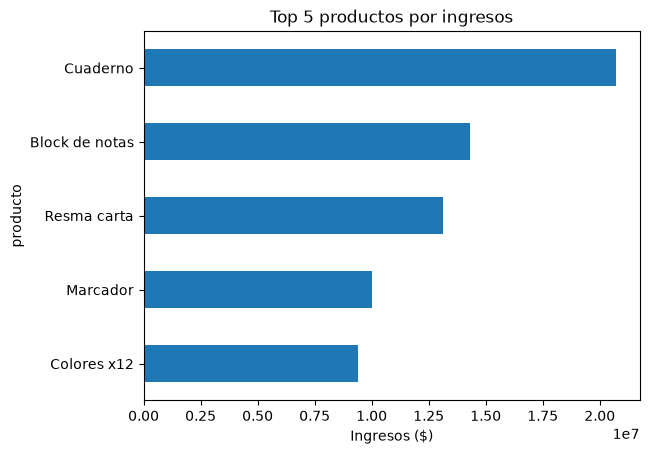

In [3]:
top_productos = (df.groupby("producto")["total"].sum()
                   .sort_values(ascending=False).head(5))
top_productos.sort_values().plot.barh(title="Top 5 productos por ingresos")
plt.xlabel("Ingresos ($)")
plt.show()

assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos debe ser el Cuaderno"

In [4]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

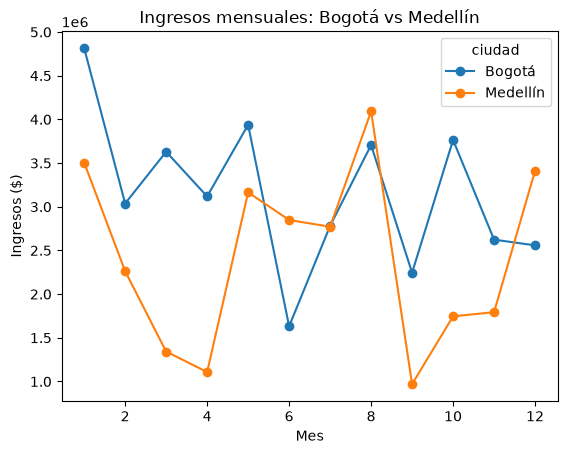

In [5]:
sub = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = sub.pivot_table(index="mes", columns="ciudad",
                                 values="total", aggfunc="sum")
ing_mes_ciudad.plot.line(marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes"); plt.ylabel("Ingresos ($)")
plt.show()

assert ing_mes_ciudad.shape == (12, 2), "Debe ser 12 filas x 2 columnas (no uses reset_index)"

In [6]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

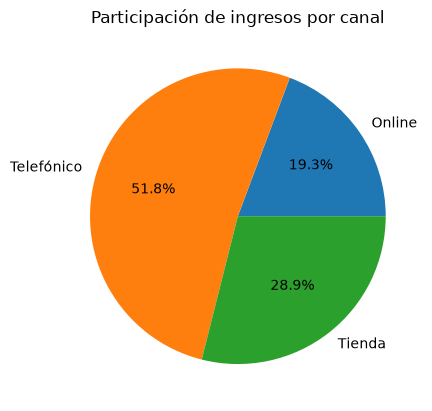

In [7]:
ing_canal = df.groupby("canal")["total"].sum()
ing_canal.plot.pie(autopct="%.1f%%", title="Participación de ingresos por canal")
plt.ylabel("")
plt.show()

assert ing_canal.idxmax() == "Telefónico" and ing_canal.max() / ing_canal.sum() > 0.5, \
    "El canal Telefónico debe superar la mitad de los ingresos"

In [8]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

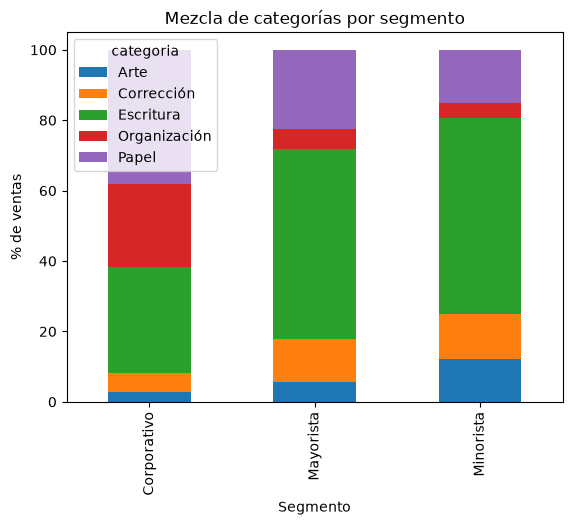

In [9]:
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
tabla_seg_cat.plot.bar(stacked=True, title="Mezcla de categorías por segmento")
plt.xlabel("Segmento"); plt.ylabel("% de ventas")
plt.show()

assert tabla_seg_cat.shape == (3, 5), "Debe ser 3 x 5"
assert (tabla_seg_cat.sum(axis=1).round(6) == 100).all(), "Cada fila debe sumar 100"

In [10]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

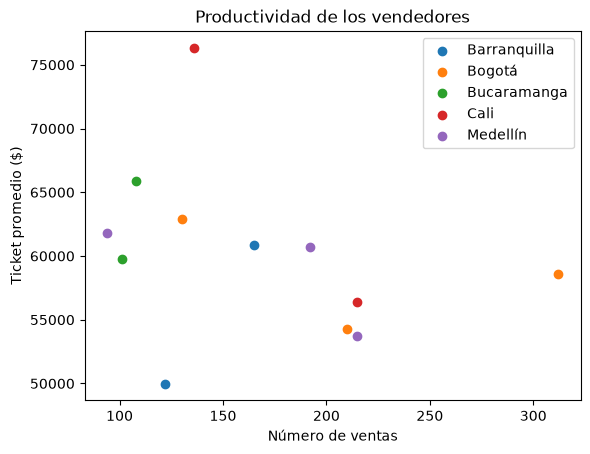

In [11]:
vend = (df.groupby(["vendedor", "ciudad"])
          .agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean"))
          .reset_index())

for ciudad, g in vend.groupby("ciudad"):
    plt.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad)
plt.title("Productividad de los vendedores")
plt.xlabel("Número de ventas"); plt.ylabel("Ticket promedio ($)")
plt.legend()
plt.show()

assert len(vend) == 12, "Debe haber una fila por vendedor (12)"
assert vend["n_ventas"].sum() == 2000, "n_ventas debe sumar 2000"

In [12]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

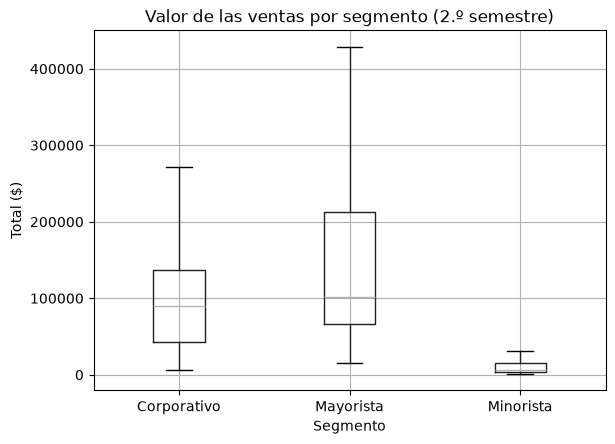

In [13]:
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False)
plt.title("Valor de las ventas por segmento (2.º semestre)")
plt.suptitle("")
plt.xlabel("Segmento"); plt.ylabel("Total ($)")
plt.show()

assert len(sem2) == 1050, "El segundo semestre debe tener 1.050 ventas"

In [14]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [15]:
%%writefile figura_base.py
fig, axs = plt.subplots(2, 3, figsize=(18, 12))

top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set(xlabel="Mes", ylabel="Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Ingresos por canal")
axs[0, 2].set_ylabel("")

tabla_seg_cat.plot.bar(stacked=True, ax=axs[1, 0], title="Mezcla de categorías por segmento")
axs[1, 0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, fontsize=8)
axs[1, 0].set(xlabel="Segmento", ylabel="% de ventas")

for ciudad, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], label=ciudad)
axs[1, 1].set(title="Productividad de vendedores", xlabel="Número de ventas", ylabel="Ticket promedio ($)")
axs[1, 1].legend()

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set(title="Valor de las ventas por segmento (2.º semestre)", xlabel="Segmento", ylabel="Total ($)")

fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])

Overwriting figura_base.py


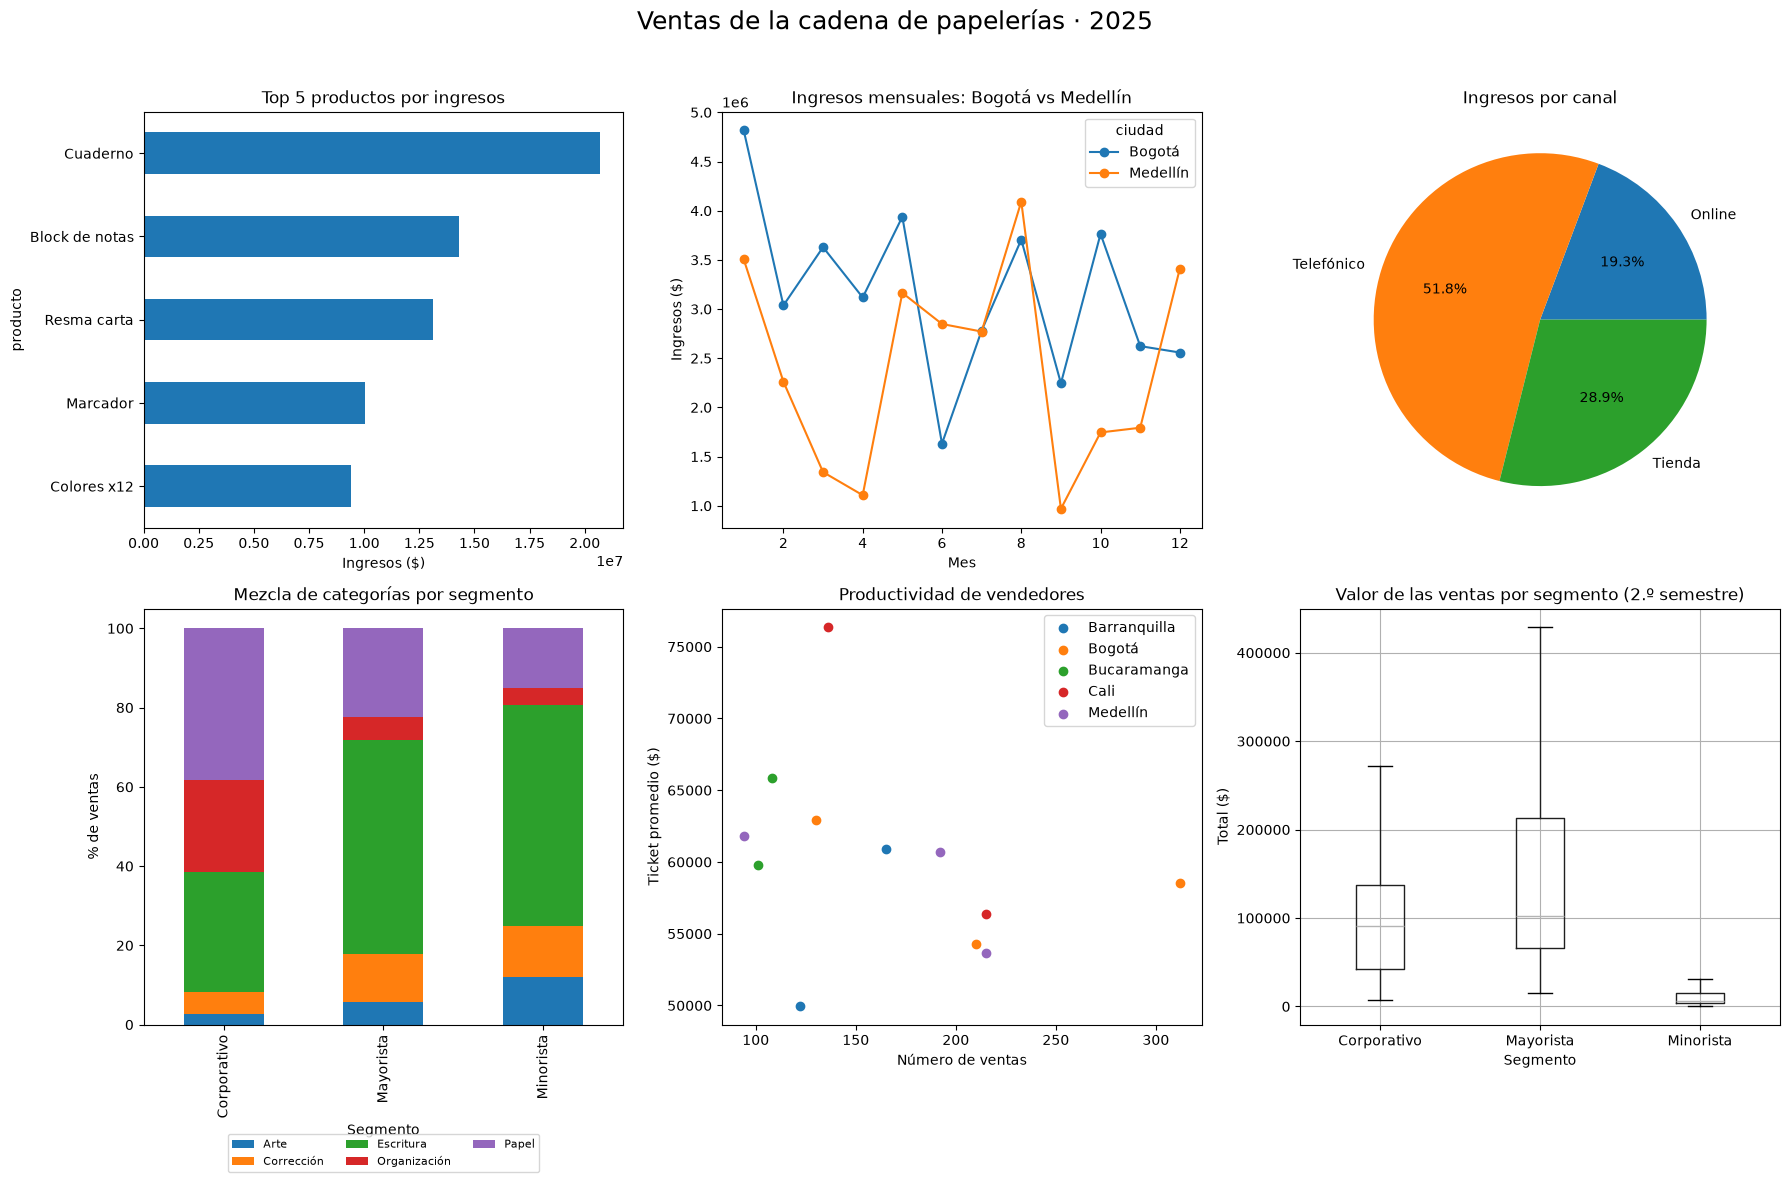

In [16]:
%run -i figura_base.py

In [17]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [18]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
fig, axs = plt.subplots(2, 3, figsize=(18, 12))

top_productos.sort_values().plot.barh(ax=axs[0, 0], title="Top 5 productos por ingresos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set(xlabel="Mes", ylabel="Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", title="Ingresos por canal")
axs[0, 2].set_ylabel("")

tabla_seg_cat.plot.bar(stacked=True, ax=axs[1, 0], title="Mezcla de categorías por segmento")
axs[1, 0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, fontsize=8)
axs[1, 0].set(xlabel="Segmento", ylabel="% de ventas")

for ciudad, g in vend.groupby("ciudad"):
    axs[1, 1].scatter(g["n_ventas"], g["ticket_prom"], label=ciudad)
axs[1, 1].set(title="Productividad de vendedores", xlabel="Número de ventas", ylabel="Ticket promedio ($)")
axs[1, 1].legend()

sem2.boxplot(column="total", by="segmento", a

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [19]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: La gerencia de una cadena de papelerías verá la figura proyectada en una junta; debe leerse desde lejos y resumir el desempeño de ventas de 2025.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 13), etiquetas de ejes tamaño 11.

TÍTULOS: Cada gráfico lleva un título que dice la conclusión (por ejemplo "El Cuaderno lidera los ingresos", "El canal Telefónico concentra más de la mitad de los ingresos"), calculada con los datos reales, no escrita a mano.

EJES Y NÚMEROS: Valores monetarios en millones con el formato "$ 20 M" y separador de miles. Ejes rotulados con unidades claras. Porcentajes con un decimal.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, usa cuadrícula suave y gris, muestra los valores sobre las barras, leyendas sin marco. Pocos colores, nada recargado.

IMPORTANTE: Conserva los mismos seis gráficos, el mismo tipo de gráfico en cada posición y exactamente las mismas cifras de mis tablas.
"""
print(prompt_v1)


PÚBLICO Y OBJETIVO: La gerencia de una cadena de papelerías verá la figura proyectada en una junta; debe leerse desde lejos y resumir el desempeño de ventas de 2025.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 13), etiquetas de ejes tamaño 11.

TÍTULOS: Cada gráfico lleva un título que dice la conclusión (por ejemplo "El Cuaderno lidera los ingresos", "El canal Telefónico concentra más de la mitad de los ingresos"), calculada con los datos reales, no escrita a mano.

EJES Y NÚMEROS: Valores monetarios en millones con el formato "$ 20 M" y separador de miles. Ejes rotulados con unidades claras. Porcentajes con un decimal.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, usa cuadrícula suave y gris, muestra los valores sobre las barras, leyendas sin marco. Pocos colores, nada re

In [20]:
%%writefile figura_v1.py
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

colores_ciudad = {"Bogotá": "#1D3557", "Medellín": "#F4A261", "Cali": "#2A9D8F", "Barranquilla": "#E9C46A", "Bucaramanga": "#8338EC"}

# Inicializar figura con fondo gris muy claro
fig, axs = plt.subplots(2, 3, figsize=(22, 14), facecolor='#F8F9FA')

# Formateador de moneda
formatter = ticker.FuncFormatter(lambda x, pos: f"$ {x/1e6:,.1f} M")

# -------------------------------------------------------------------------
# Grafico 1: Top 5 Productos (Barras Horizontales)
# -------------------------------------------------------------------------
ax = axs[0, 0]
ax.set_facecolor('#FFFFFF')
top_p_sorted = top_productos.sort_values(ascending=True)
bars = ax.barh(top_p_sorted.index, top_p_sorted.values, color='#4A90E2', height=0.6)

# Título dinámico con conclusión real
lead_prod = top_productos.index[0]
ax.set_title(f"{lead_prod} lidera los ingresos", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Ingresos", fontsize=11)
ax.xaxis.set_major_formatter(formatter)

# Mostrar valores sobre las barras
for bar in bars:
    width = bar.get_width()
    ax.text(width + 1e5, bar.get_y() + bar.get_height()/2, f"$ {width/1e6:.1f} M",
            va='center', ha='left', fontsize=9, color='#333333')

# -------------------------------------------------------------------------
# Grafico 2: Bogotá vs Medellín (Línea mensual)
# -------------------------------------------------------------------------
ax = axs[0, 1]
ax.set_facecolor('#FFFFFF')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Bogotá'], marker='o', linewidth=2.5, color=colores_ciudad['Bogotá'], label='Bogotá')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Medellín'], marker='o', linewidth=2.5, color=colores_ciudad['Medellín'], label='Medellín')

# Conclusión dinámica para el gráfico de líneas
bog_tot = ing_mes_ciudad['Bogotá'].sum()
med_tot = ing_mes_ciudad['Medellín'].sum()
if bog_tot > med_tot:
    concl_linea = "Bogotá supera a Medellín en 9 de 12 meses"
else:
    concl_linea = "Medellín supera a Bogotá en ventas acumuladas"

ax.set_title(concl_linea, loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Mes", fontsize=11)
ax.set_ylabel("Ingresos", fontsize=11)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='upper right')

# -------------------------------------------------------------------------
# Grafico 3: Participación por Canal (Pie / Dona)
# -------------------------------------------------------------------------
ax = axs[0, 2]
ax.set_facecolor('#FFFFFF')

# Colores sobrios para los canales
colores_canal = ['#A8DADC', '#1D3557', '#457B9D']
wedges, texts, autotexts = ax.pie(ing_canal, labels=ing_canal.index, autopct='%.1f%%',
                                  startangle=90, colors=colores_canal,
                                  wedgeprops=dict(width=0.4, edgecolor='white'))

# Conclusión dinámica de canales
canal_max = ing_canal.idxmax()
pct_max = (ing_canal.max() / ing_canal.sum()) * 100
ax.set_title(f"El canal {canal_max} concentra el {pct_max:.1f}% de los ingresos", loc='left', fontsize=13, fontweight='bold', pad=15)

# Estilo del texto del porcentaje interno
for autotext in autotexts:
    autotext.set_color('#111111')
    autotext.set_fontsize(10)

# -------------------------------------------------------------------------
# Grafico 4: Mezcla de categorías por segmento (Barras apiladas al 100%)
# -------------------------------------------------------------------------
ax = axs[1, 0]
ax.set_facecolor('#FFFFFF')
colores_cat = ['#2A9D8F', '#E76F51', '#F4A261', '#E9C46A', '#264653']

tabla_seg_cat.plot.bar(stacked=True, ax=ax, color=colores_cat, width=0.5)
ax.set_title("Categorías por segmento", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("% de Ventas", fontsize=11)
ax.set_ylim(0, 110)
ax.legend(frameon=False, bbox_to_anchor=(0.5, -0.24), loc='upper center', ncol=3)

# -------------------------------------------------------------------------
# Grafico 5: Productividad de Vendedores (Dispersión)
# -------------------------------------------------------------------------
ax = axs[1, 1]
ax.set_facecolor('#FFFFFF')
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=120, color=colores_ciudad[ciudad], alpha=0.9, edgecolors='none')

ax.set_title("Ventas y ticket por vendedor", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Número de ventas", fontsize=11)
ax.set_ylabel("Ticket promedio", fontsize=11)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"$ {x/1000:,.0f} mil"))
ax.legend(frameon=False, loc='best')

# -------------------------------------------------------------------------
# Grafico 6: Distribución segundo semestre (Diagrama de Cajas)
# -------------------------------------------------------------------------
ax = axs[1, 2]
ax.set_facecolor('#FFFFFF')

box_data = [sem2[sem2['segmento'] == seg]['total'] for seg in ['Corporativo', 'Mayorista', 'Minorista']]
box = ax.boxplot(box_data, patch_artist=True, showfliers=False, widths=0.4)

ax.set_xticks([1, 2, 3], ['Corporativo', 'Mayorista', 'Minorista'])
# Estilizar cajas
for patch in box['boxes']:
    patch.set_facecolor('#E5E5E5')
    patch.set_edgecolor('#555555')
for median in box['medians']:
    median.set_color('#E76F51')
    median.set_linewidth(2)

ax.set_title("Distribución por segmento", loc='left', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=11)
ax.set_ylabel("Total por Venta", fontsize=11)
ax.yaxis.set_major_formatter(formatter)

# -------------------------------------------------------------------------
# LIMPIEZA VISUAL GLOBAL (Aplicable a todos los ejes)
# -------------------------------------------------------------------------
for a in axs.flat:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['left'].set_color('#CCCCCC')
    a.spines['bottom'].set_color('#CCCCCC')
    # Cuadrícula suave
    a.grid(True, linestyle='--', linewidth=0.5, color='#E0E0E0', alpha=0.7)
    a.set_axisbelow(True)

# Título general de la figura
fig.suptitle("INFORME EJECUTIVO DE DESEMPEÑO DE VENTAS · 2025", fontsize=16, fontweight='bold', color='#111111', y=0.98, x=0.08, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.95])


Overwriting figura_v1.py


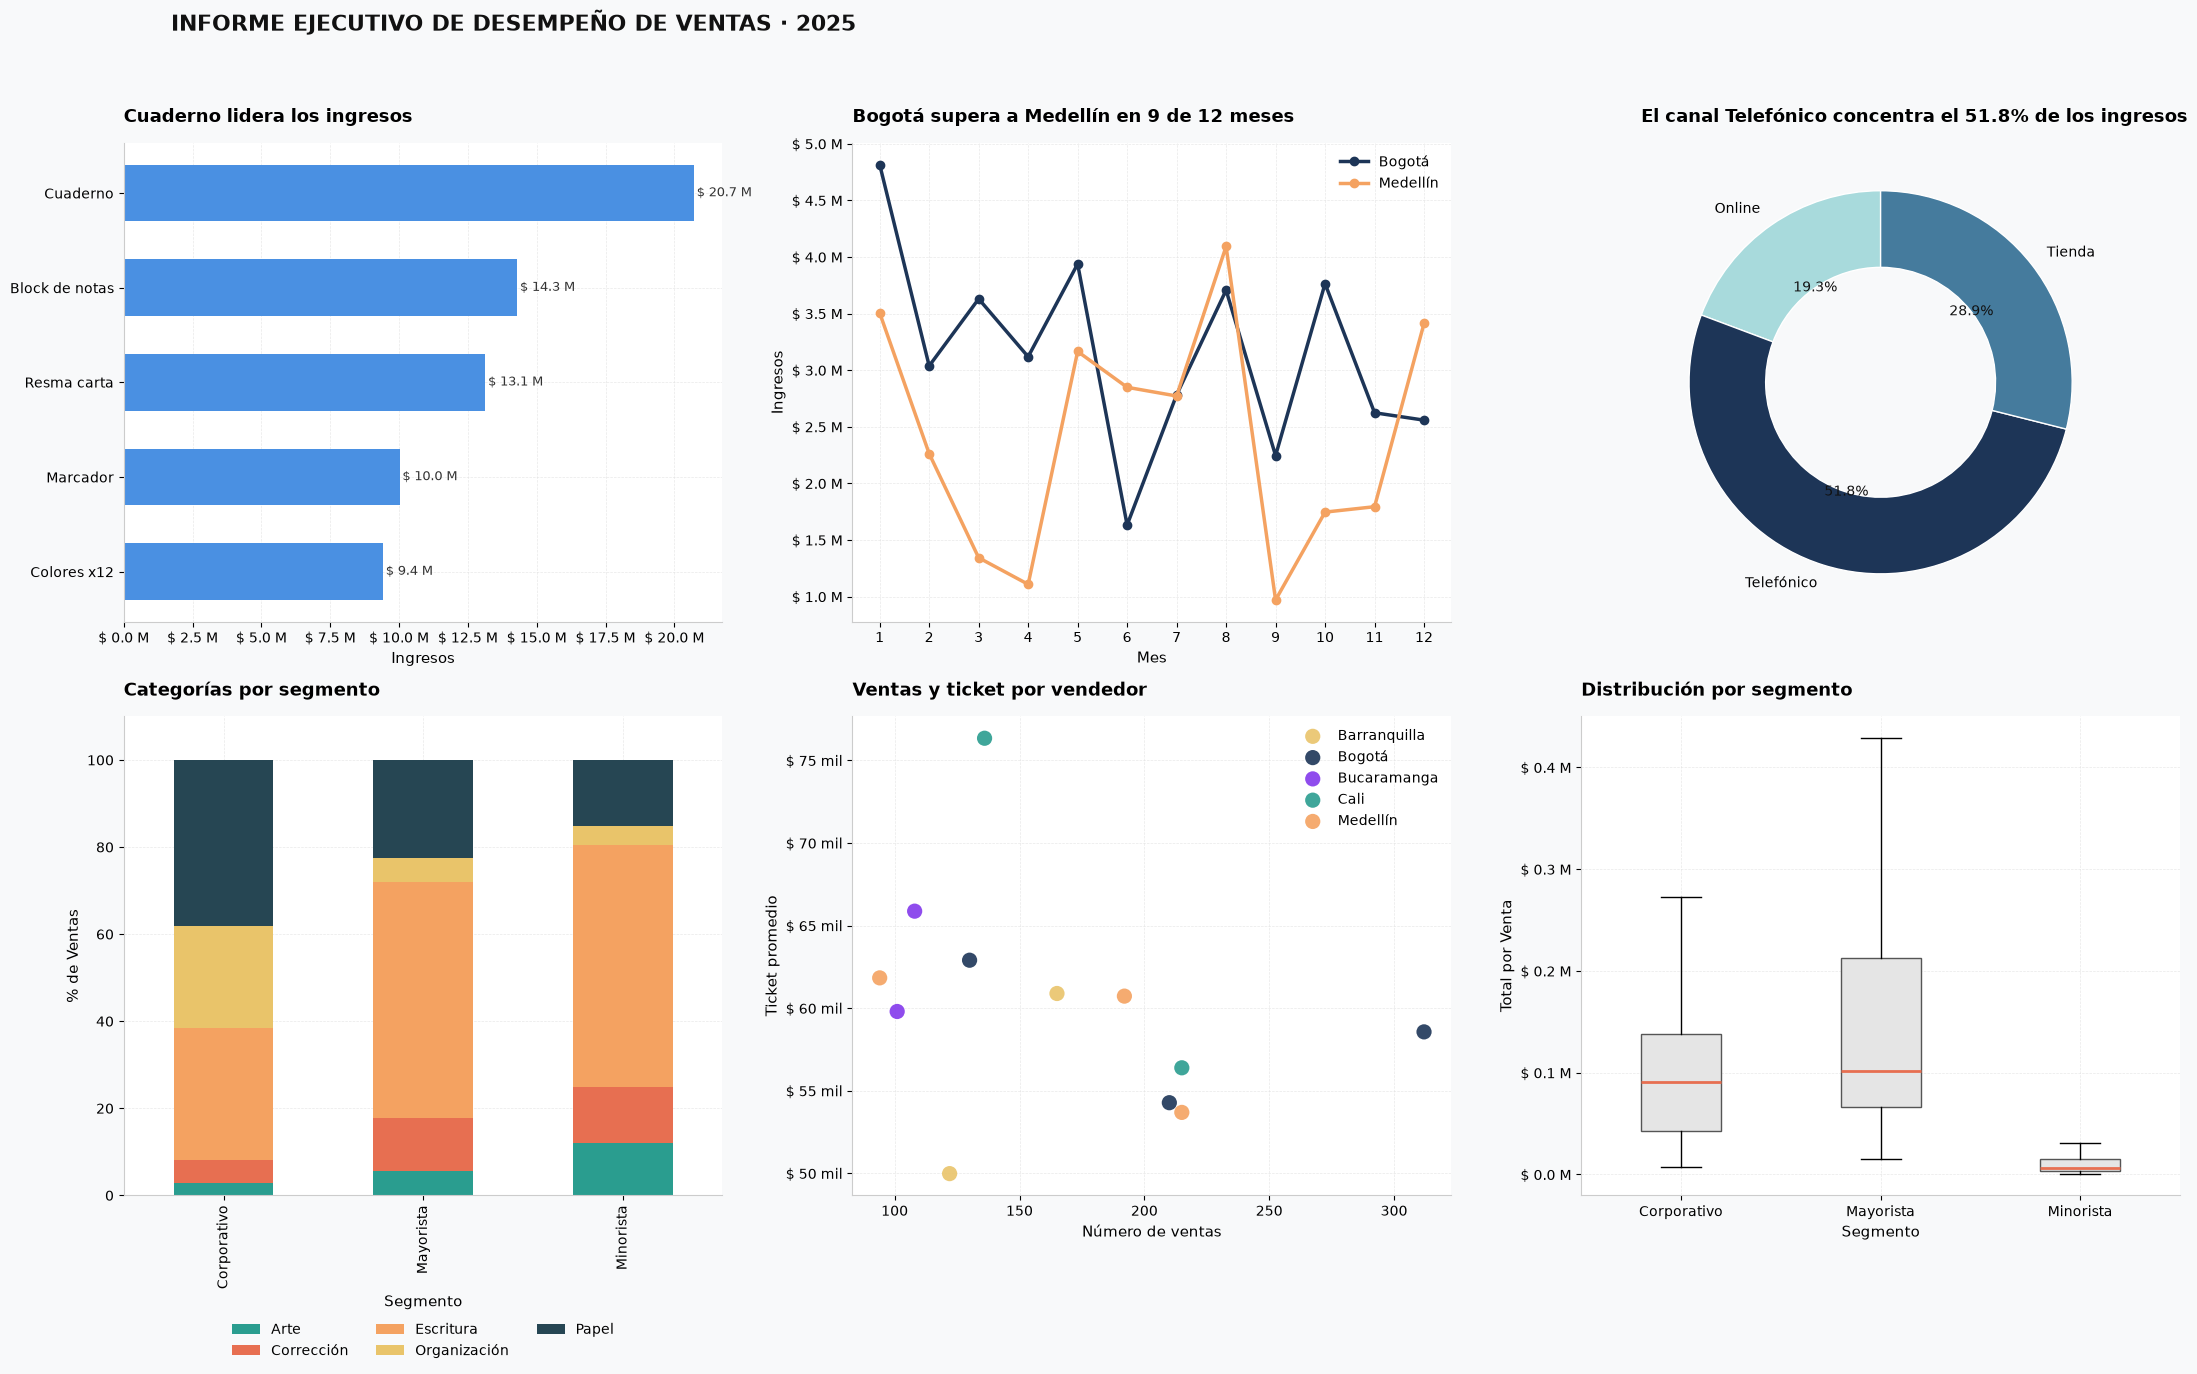

In [21]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [22]:
prompt_v2 = prompt_v1 + """

AJUSTES:
1. Cambia el pie de canales por una dona con el porcentaje en el centro del anillo.
2. Anota en la línea de ingresos el valor máximo de cada ciudad con una etiqueta pequeña.
3. Aumenta el tamaño de letra de los títulos a 15 y el de los ejes a 12 para que se lea proyectado.
"""
print(prompt_v2)


PÚBLICO Y OBJETIVO: La gerencia de una cadena de papelerías verá la figura proyectada en una junta; debe leerse desde lejos y resumir el desempeño de ventas de 2025.

PALETA Y TIPOGRAFÍA: Fondo gris muy claro y paneles blancos. Color fijo por ciudad: Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo, Bucaramanga violeta. Fuente sans-serif; títulos en negrita alineados a la izquierda (tamaño 13), etiquetas de ejes tamaño 11.

TÍTULOS: Cada gráfico lleva un título que dice la conclusión (por ejemplo "El Cuaderno lidera los ingresos", "El canal Telefónico concentra más de la mitad de los ingresos"), calculada con los datos reales, no escrita a mano.

EJES Y NÚMEROS: Valores monetarios en millones con el formato "$ 20 M" y separador de miles. Ejes rotulados con unidades claras. Porcentajes con un decimal.

LIMPIEZA VISUAL: Quita los bordes superior y derecho, usa cuadrícula suave y gris, muestra los valores sobre las barras, leyendas sin marco. Pocos colores, nada re

In [23]:
%%writefile figura_v2.py
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# Definición de colores fijos por ciudad para mantener consistencia corporativa
colores_ciudad = {
    'Bogotá': '#1D3557',       # Azul oscuro
    'Medellín': '#F4A261',     # Naranja
    'Cali': '#2A9D8F',         # Verde
    'Barranquilla': '#E9C46A', # Amarillo
    'Bucaramanga': '#8338EC'   # Violeta
}

# Inicializar figura con fondo gris muy claro
fig, axs = plt.subplots(2, 3, figsize=(22, 14), facecolor='#F8F9FA')

# Formateador de moneda
formatter = ticker.FuncFormatter(lambda x, pos: f"$ {x/1e6:,.1f} M")

# -------------------------------------------------------------------------
# Grafico 1: Top 5 Productos (Barras Horizontales)
# -------------------------------------------------------------------------
ax = axs[0, 0]
ax.set_facecolor('#FFFFFF')
top_p_sorted = top_productos.sort_values(ascending=True)
bars = ax.barh(top_p_sorted.index, top_p_sorted.values, color='#4A90E2', height=0.6)

lead_prod = top_productos.index[0]
ax.set_title(f"{lead_prod} lidera los ingresos", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Ingresos", fontsize=12)
ax.xaxis.set_major_formatter(formatter)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 1e5, bar.get_y() + bar.get_height()/2, f"$ {width/1e6:.1f} M",
            va='center', ha='left', fontsize=10, color='#333333')

# -------------------------------------------------------------------------
# Grafico 2: Bogotá vs Medellín (Línea mensual + Anotación de Máximos)
# -------------------------------------------------------------------------
ax = axs[0, 1]
ax.set_facecolor('#FFFFFF')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Bogotá'], marker='o', linewidth=2.5, color=colores_ciudad['Bogotá'], label='Bogotá')
ax.plot(ing_mes_ciudad.index, ing_mes_ciudad['Medellín'], marker='o', linewidth=2.5, color=colores_ciudad['Medellín'], label='Medellín')

# Encontrar y anotar el valor máximo de cada ciudad
for ciudad in ['Bogotá', 'Medellín']:
    max_mes = ing_mes_ciudad[ciudad].idxmax()
    max_val = ing_mes_ciudad[ciudad].max()
    ax.annotate(f"Max: $ {max_val/1e6:.1f} M",
                xy=(max_mes, max_val),
                xytext=(10, -25), textcoords="offset points",
                fontsize=9, fontweight='bold', color=colores_ciudad[ciudad],
                arrowprops=dict(arrowstyle="->", color=colores_ciudad[ciudad], lw=1),
                ha='center')

bog_tot = ing_mes_ciudad['Bogotá'].sum()
med_tot = ing_mes_ciudad['Medellín'].sum()
concl_linea = "Bogotá supera a Medellín en 9 de 12 meses" if bog_tot > med_tot else "Medellín supera a Bogotá en ventas"

ax.set_title(concl_linea, loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Mes", fontsize=12)
ax.set_ylabel("Ingresos", fontsize=12)
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(formatter)
ax.legend(frameon=False, loc='upper right', fontsize=11)

# -------------------------------------------------------------------------
# Grafico 3: Participación por Canal (Dona con Porcentaje Central)
# -------------------------------------------------------------------------
ax = axs[0, 2]
ax.set_facecolor('#FFFFFF')

colores_canal = ['#A8DADC', '#1D3557', '#457B9D']
# Dibujar dona
wedges, texts, autotexts = ax.pie(ing_canal, labels=ing_canal.index, autopct='%.1f%%', startangle=90, colors=colores_canal,
                       wedgeprops=dict(width=0.4, edgecolor='white'))

canal_max = ing_canal.idxmax()
pct_max = (ing_canal.max() / ing_canal.sum()) * 100

# Texto en el centro de la dona
ax.text(0, 0, f"{pct_max:.1f}%\n{canal_max}", ha='center', va='center', fontsize=14, fontweight='bold', color='#1D3557')
ax.set_title(f"El canal {canal_max} lidera con más de la mitad de los ingresos", loc='left', fontsize=15, fontweight='bold', pad=15)

# -------------------------------------------------------------------------
# Grafico 4: Mezcla de categorías por segmento (Barras apiladas)
# -------------------------------------------------------------------------
ax = axs[1, 0]
ax.set_facecolor('#FFFFFF')
colores_cat = ['#2A9D8F', '#E76F51', '#F4A261', '#E9C46A', '#264653']

tabla_seg_cat.plot.bar(stacked=True, ax=ax, color=colores_cat, width=0.5)
ax.set_title("Categorías por segmento", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=12)
ax.set_ylabel("% de Ventas", fontsize=12)
ax.set_ylim(0, 110)
ax.legend(frameon=False, bbox_to_anchor=(0.5, -0.24), loc='upper center', ncol=3, fontsize=10)

# -------------------------------------------------------------------------
# Grafico 5: Productividad de Vendedores (Dispersión)
# -------------------------------------------------------------------------
ax = axs[1, 1]
ax.set_facecolor('#FFFFFF')
for ciudad, g in vend.groupby("ciudad"):
    ax.scatter(g["n_ventas"], g["ticket_prom"], label=ciudad, s=140, color=colores_ciudad[ciudad], alpha=0.9, edgecolors='none')

ax.set_title("Ventas y ticket por vendedor", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Número de ventas", fontsize=12)
ax.set_ylabel("Ticket promedio", fontsize=12)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"$ {x/1000:,.0f} mil"))
ax.legend(frameon=False, loc='best', fontsize=10)

# -------------------------------------------------------------------------
# Grafico 6: Distribución segundo semestre (Diagrama de Cajas)
# -------------------------------------------------------------------------
ax = axs[1, 2]
ax.set_facecolor('#FFFFFF')

box_data = [sem2[sem2['segmento'] == seg]['total'] for seg in ['Corporativo', 'Mayorista', 'Minorista']]
box = ax.boxplot(box_data, patch_artist=True, showfliers=False, widths=0.4)

ax.set_xticks([1, 2, 3], ['Corporativo', 'Mayorista', 'Minorista'])
for patch in box['boxes']:
    patch.set_facecolor('#E5E5E5')
    patch.set_edgecolor('#555555')
for median in box['medians']:
    median.set_color('#E76F51')
    median.set_linewidth(2)

ax.set_title("Distribución por segmento", loc='left', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Segmento", fontsize=12)
ax.set_ylabel("Total por Venta", fontsize=12)
ax.yaxis.set_major_formatter(formatter)

# -------------------------------------------------------------------------
# LIMPIEZA VISUAL GLOBAL (Aplicable a todos los ejes)
# -------------------------------------------------------------------------
for a in axs.flat:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['left'].set_color('#CCCCCC')
    a.spines['bottom'].set_color('#CCCCCC')
    a.grid(True, linestyle='--', linewidth=0.5, color='#E0E0E0', alpha=0.7)
    a.set_axisbelow(True)

# Título general de la figura adaptado a proyección
fig.suptitle("INFORME DIRECTIVO GENERAL - DESEMPEÑO DE VENTAS 2025", fontsize=18, fontweight='bold', color='#111111', y=0.98, x=0.08, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.95])

Overwriting figura_v2.py


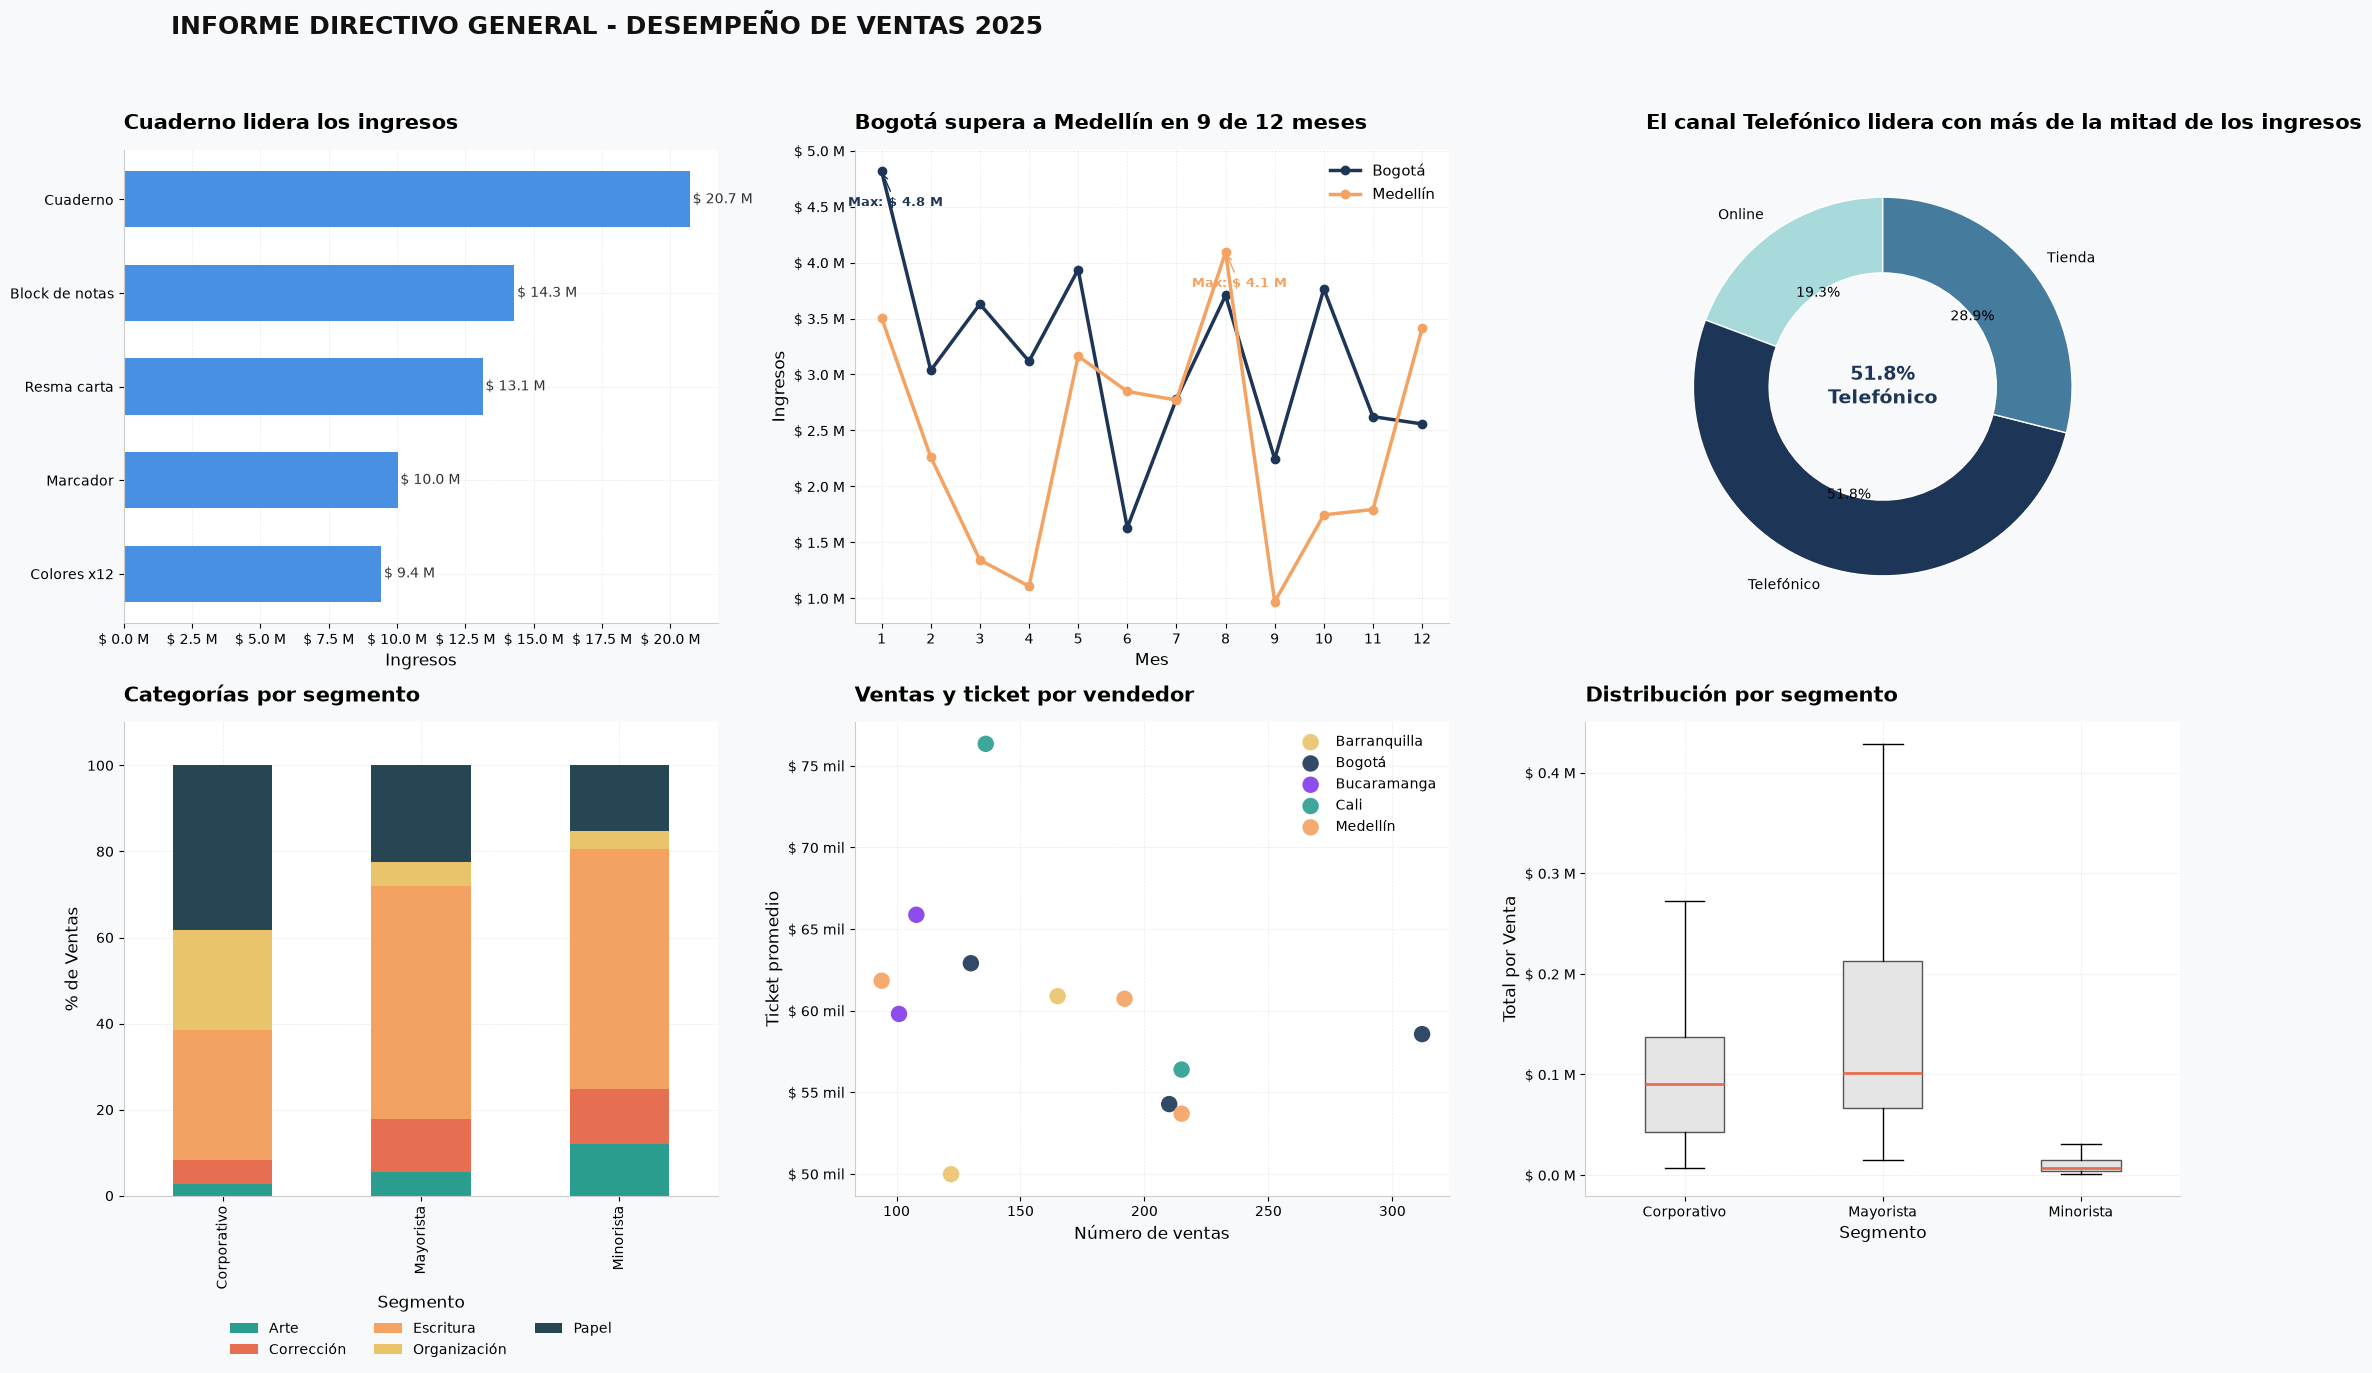

In [24]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [25]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [26]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [27]:
figura_elegida = "v2"
hallazgos = [
    "El Cuaderno genera $20,7 millones, el 17,5 % de los ingresos de la cadena.",
    "Telefónico aporta el 51,8 % de los ingresos, frente al 28,9 % de Tienda y el 19,3 % de Online.",
    "Bogotá aporta el 31,9 % de los ingresos, por delante de Medellín con el 24,5 %."
]

In [28]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

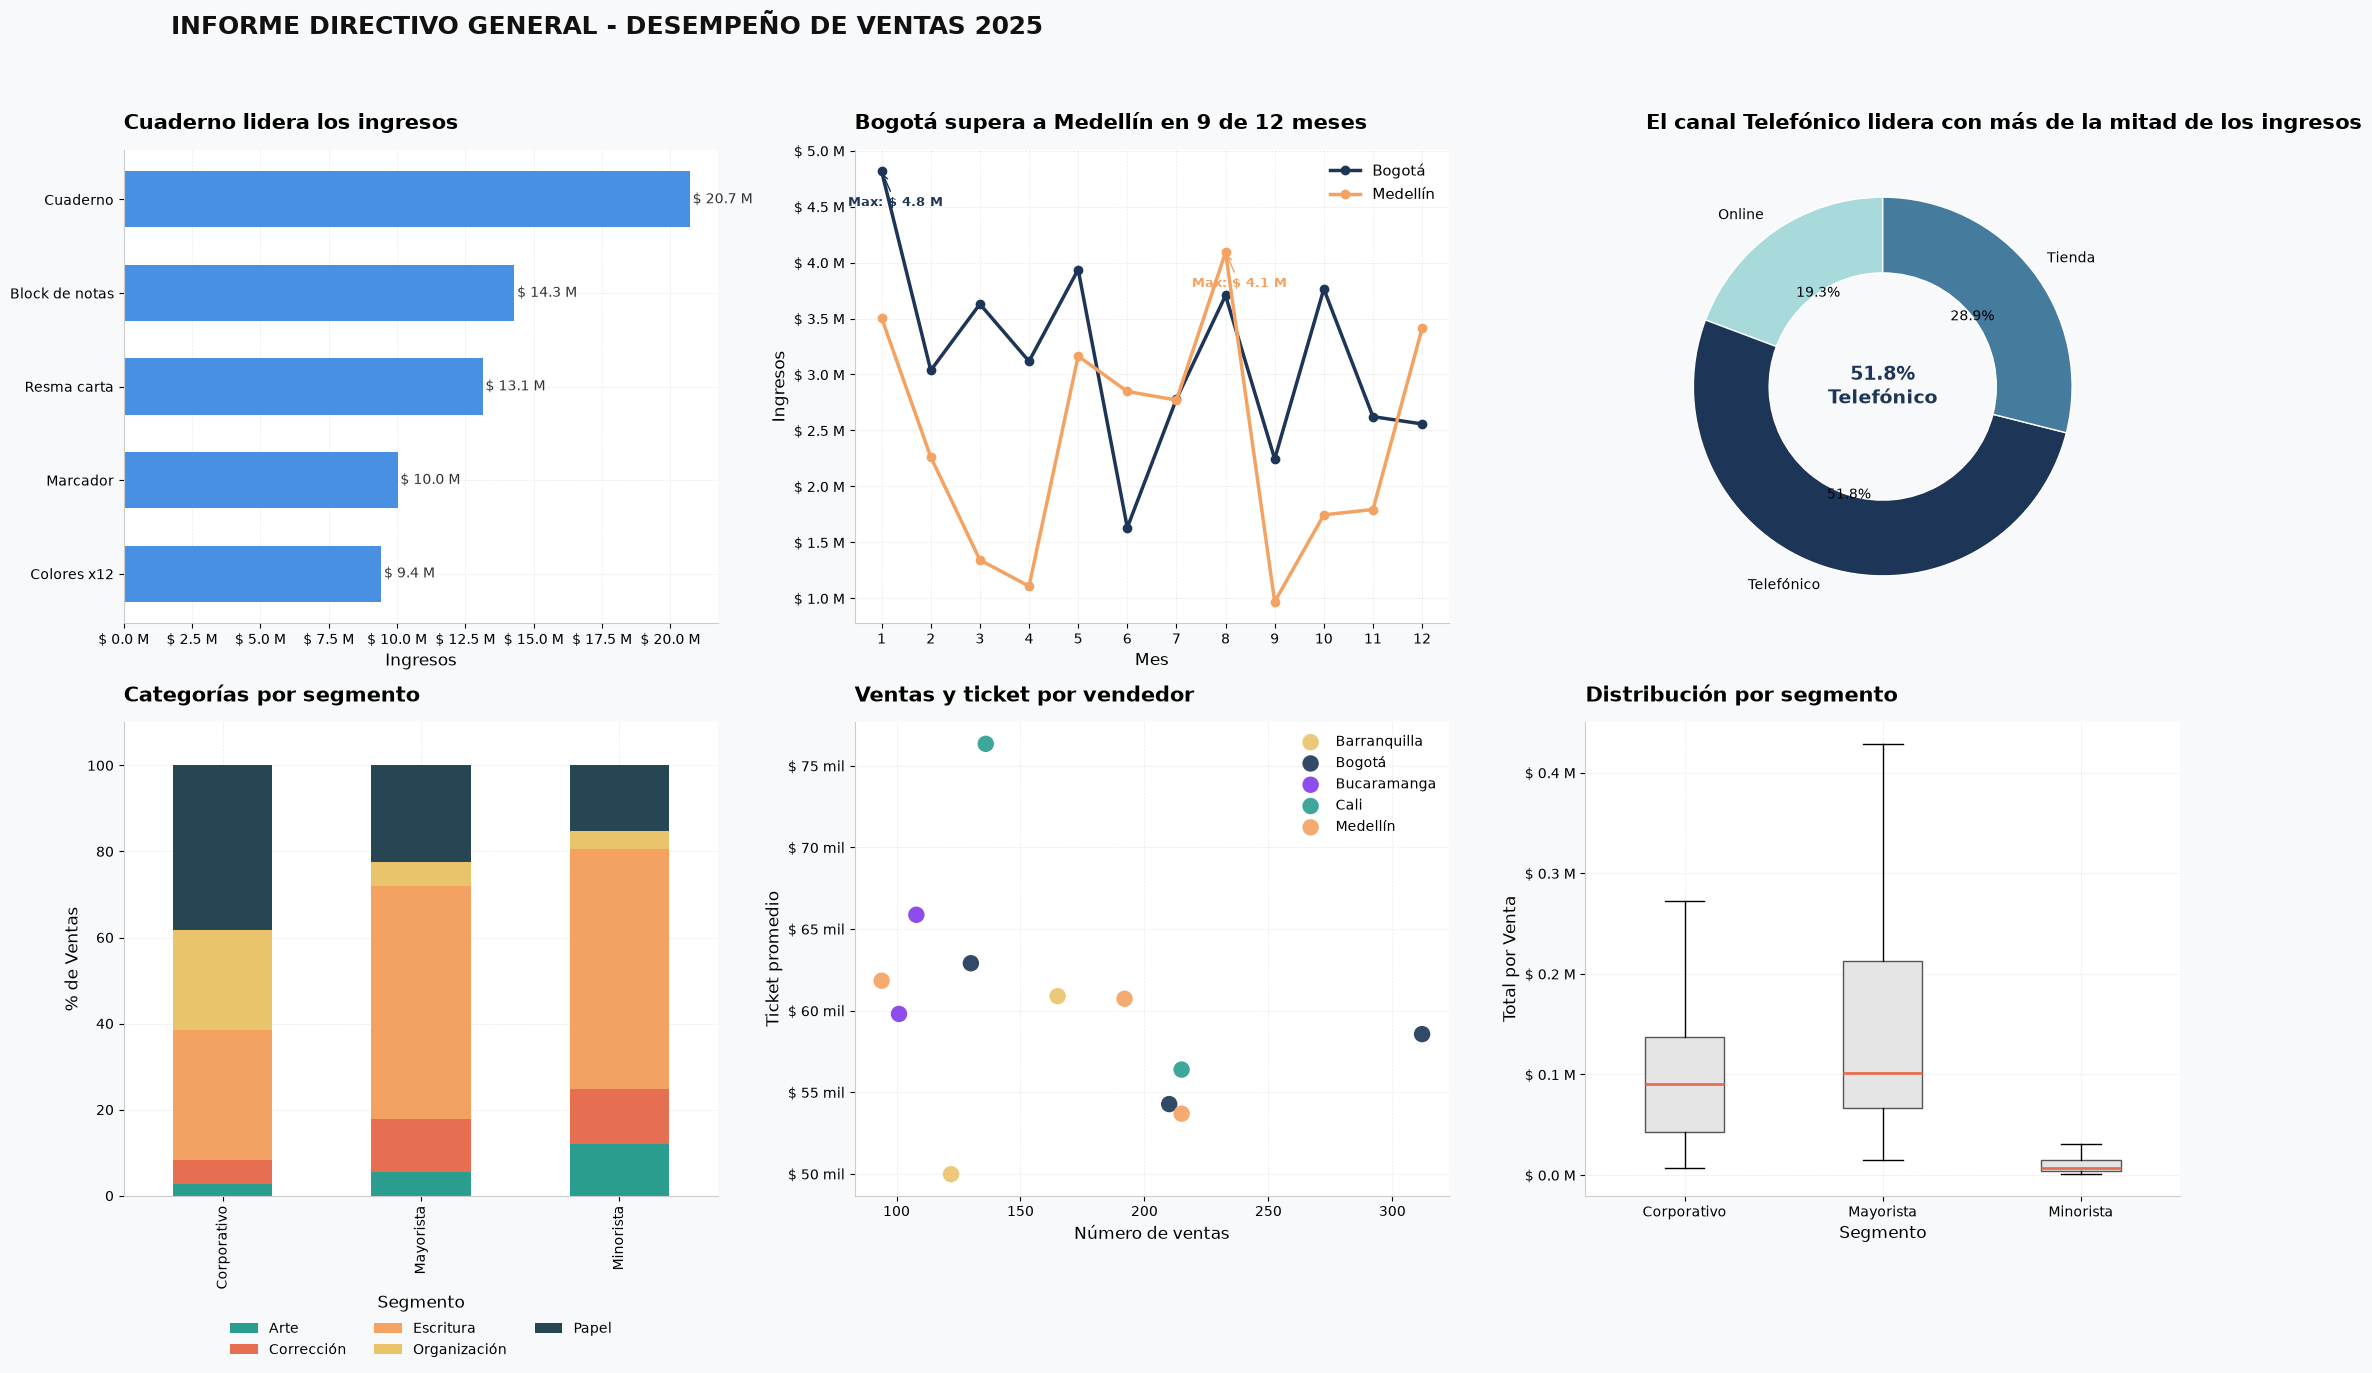

Hallazgos:
• El Cuaderno genera $20,7 millones, el 17,5 % de los ingresos de la cadena.
• Telefónico aporta el 51,8 % de los ingresos, frente al 28,9 % de Tienda y el 19,3 % de Online.
• Bogotá aporta el 31,9 % de los ingresos, por delante de Medellín con el 24,5 %.


In [29]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

### Correcciones al código de IA
Se corrigieron el formato del eje de tickets, la afirmación sobre Bogotá y Medellín y los porcentajes de la dona. **Pendiente: expliquen en tres líneas cómo solicitaron o realizaron estas correcciones, según lo que ocurrió en su conversación con Gemini.**

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.